### **Clase Practica: Distribuciones**

In [25]:
# Librerias usadas 
import pandas as pd 
import openpyxl
import numpy as np
# para prueba jacque bera
from statsmodels.stats.stattools import jarque_bera
import matplotlib.pyplot as plt
from scipy.stats import norm

In [7]:
# Cargue de la base de datos original
df_acciones = pd.read_excel("Material_practico_2026-II.xlsx")
df_acciones

# Combertir JP Morgan a pesos Colombianos
df_acciones['J.P. Morgan Chase (COP)'] = round(df_acciones['J.P. Morgan Chase (USD)']*df_acciones['TRM (COP)'],0)
df_acciones

,Fecha,Bancolombia (P) (COP),J.P. Morgan Chase (USD),TRM (COP),J.P. Morgan Chase (COP)
0,2015-01-02,16600.0,39.69,2284.22,90661.0
1,2015-01-03,17000.0,40.19,2284.22,91803.0
2,2015-01-04,16700.0,39.62,2282.27,90424.0
3,2015-01-05,17000.0,39.74,2282.13,90692.0
4,2015-01-06,16900.0,40.02,2279.99,91245.0
...,...,...,...,...,...
2469,2025-12-14,26900.0,84.76,2982.29,252779.0
2470,2025-12-15,27800.0,84.73,2964.56,251187.0
2471,2025-12-19,27240.0,84.94,2997.20,254582.0
2472,2025-12-27,26920.0,87.05,2996.60,260854.0


In [8]:
# Calculo de los rendimientos 
df_rendimiento = df_acciones.set_index('Fecha').sort_index()

# Calcular (dato_actual - dato_anterior) / dato_anterior para todas las columnas
columnas_precios = ['Bancolombia (P) (COP)', 'J.P. Morgan Chase (USD)', 'TRM (COP)', 'J.P. Morgan Chase (COP)']

for col in columnas_precios:
    df_rendimiento[f'Rend_{col}'] = np.log(df_rendimiento[col] / df_rendimiento[col].shift(1)).round(4) #np.log(df_rendimiento[col].pct_change().round(4))


df_rendimiento

,Bancolombia (P) (COP),J.P. Morgan Chase (USD),TRM (COP),J.P. Morgan Chase (COP),Rend_Bancolombia (P) (COP),Rend_J.P. Morgan Chase (USD),Rend_TRM (COP),Rend_J.P. Morgan Chase (COP)
Fecha,,,,,,,,
2015-01-02,16600.0,39.69,2284.22,90661.0,NaN,NaN,NaN,NaN
2015-01-03,17000.0,40.19,2284.22,91803.0,0.0238,0.0125,0.0000,0.0125
2015-01-04,16700.0,39.62,2282.27,90424.0,-0.0178,-0.0143,-0.0009,-0.0151
2015-01-05,17000.0,39.74,2282.13,90692.0,0.0178,0.0030,-0.0001,0.0030
2015-01-06,16900.0,40.02,2279.99,91245.0,-0.0059,0.0070,-0.0009,0.0061
...,...,...,...,...,...,...,...,...
2025-12-14,26900.0,84.76,2982.29,252779.0,-0.0148,0.0004,-0.0006,-0.0002
2025-12-15,27800.0,84.73,2964.56,251187.0,0.0329,-0.0004,-0.0060,-0.0063
2025-12-19,27240.0,84.94,2997.20,254582.0,-0.0203,0.0025,0.0109,0.0134


### **Construcción del portafolio**

In [9]:
# Cantidad de dinero a invertir en cada acción
Cantidad_Banc = 1200
Cantidad_JP = 1000
Cantidad_TRM = 20000

# Precio de las acciones en la ultima fecha de cierre de la base de datos

precio_banc , precio_JP, precio_TRM = df_rendimiento.sort_values(by = "Fecha", ascending=False).head(1)['Bancolombia (P) (COP)'].iloc[0],\
df_rendimiento.sort_values(by = "Fecha", ascending=False).head(1)['J.P. Morgan Chase (COP)'].iloc[0],\
    df_rendimiento.sort_values(by = "Fecha", ascending=False).head(1)['TRM (COP)'].iloc[0]

# Pesos del portafolio 
w_banc = Cantidad_Banc*precio_banc
w_JP = Cantidad_JP*precio_JP
w_TRM = Cantidad_TRM*precio_TRM

portafolio = w_banc + w_JP + w_TRM

# % de pesos del portafolio
w_banc_prop = w_banc / portafolio *100
w_JP_prop = w_JP / portafolio *100
w_TRM_prop = w_TRM / portafolio *100

df_rendimiento.shape

(2474, 8)

In [10]:
print("Precio Bancolombia: ", precio_banc,"precio_JP: ", precio_JP, "precio_TRM: ", precio_TRM)
print("Pesos Bancolombia: ", w_banc,"Pesos JP: ", w_JP, "Pesos TRM: ", w_TRM)
print("pesos%% de Bancolombia: ", w_banc_prop,"pesos%% JP: ", w_JP_prop, "pesos%% TRM: ", w_TRM_prop)

Precio Bancolombia:  27460.0 precio_JP:  260764.0 precio_TRM:  2992.81
Pesos Bancolombia:  32952000.0 Pesos JP:  260764000.0 Pesos TRM:  59856200.0
pesos%% de Bancolombia:  9.319737241785411 pesos%% JP:  73.75127343156504 pesos%% TRM:  16.92898932664955


In [11]:
# Calculo del rendimeinto del portafolio
cols_rend = ['Rend_Bancolombia (P) (COP)', 'Rend_J.P. Morgan Chase (COP)','Rend_TRM (COP)']
pesos = [w_banc_prop, w_JP_prop, w_TRM_prop]

df_rendimiento['Rend_Portafolio'] = df_rendimiento[cols_rend].dot(pesos)/100
df_rendimiento

,Bancolombia (P) (COP),J.P. Morgan Chase (USD),TRM (COP),J.P. Morgan Chase (COP),Rend_Bancolombia (P) (COP),Rend_J.P. Morgan Chase (USD),Rend_TRM (COP),Rend_J.P. Morgan Chase (COP),Rend_Portafolio
Fecha,,,,,,,,,
2015-01-02,16600.0,39.69,2284.22,90661.0,NaN,NaN,NaN,NaN,NaN
2015-01-03,17000.0,40.19,2284.22,91803.0,0.0238,0.0125,0.0000,0.0125,0.011437
2015-01-04,16700.0,39.62,2282.27,90424.0,-0.0178,-0.0143,-0.0009,-0.0151,-0.012948
2015-01-05,17000.0,39.74,2282.13,90692.0,0.0178,0.0030,-0.0001,0.0030,0.003855
2015-01-06,16900.0,40.02,2279.99,91245.0,-0.0059,0.0070,-0.0009,0.0061,0.003797
...,...,...,...,...,...,...,...,...,...
2025-12-14,26900.0,84.76,2982.29,252779.0,-0.0148,0.0004,-0.0006,-0.0002,-0.001628
2025-12-15,27800.0,84.73,2964.56,251187.0,0.0329,-0.0004,-0.0060,-0.0063,-0.002596
2025-12-19,27240.0,84.94,2997.20,254582.0,-0.0203,0.0025,0.0109,0.0134,0.009836


In [ ]:
### prueba de normalaidad jarque bera

jarque_bera(df_rendimiento['Rend_Portafolio'].dropna())
print("p-value: ", jarque_bera(df_rendimiento['Rend_Portafolio'].dropna())[1])
print("Estadistico: ", jarque_bera(df_rendimiento['Rend_Portafolio'].dropna())[0])
print("Valor crítico: ", 5.99)

# P-value < 0.05, por lo tanto se rechaza la hipótesis nula de normalidad.

p-value:  0.0
Estadistico:  14787.03794437744
Valor crítico:  5.99


<Axes: title={'center': 'Rendimientos Diarios - Bancolombia'}, xlabel='Fecha'>

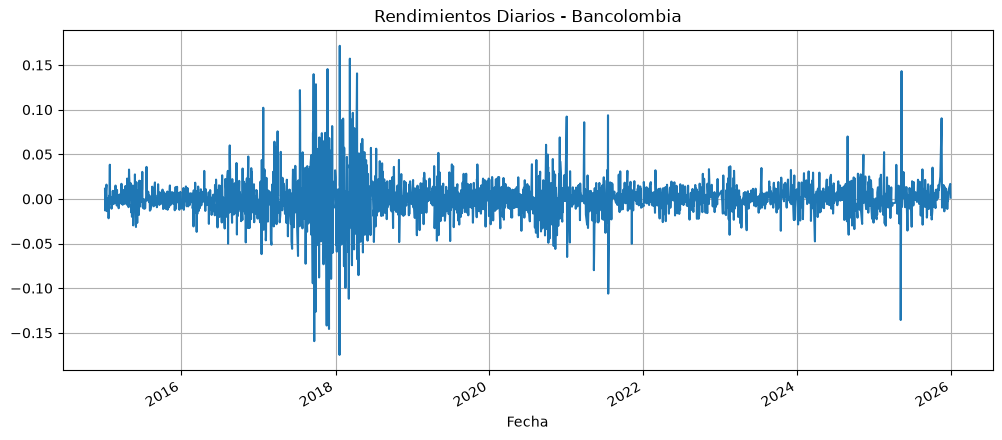

In [18]:
### Grafico de los rendimientos del portafolio

df_rendimiento['Rend_Portafolio'].plot(figsize=(12, 5), title='Rendimientos Diarios - Bancolombia', grid=True)

In [30]:
## Calculo de volatilidad historica del portafolio
volatilidad = np.std(df_rendimiento['Rend_Portafolio'].dropna())
promedio = np.mean(df_rendimiento['Rend_Portafolio'].dropna())
n_con = 0.95
z = norm.interval(n_con)


In [34]:
print("volatilidad historica del portafolio: ", volatilidad*100)
print("promedio historico del portafolio: ", promedio*100)
print("Z: ", z[1])

volatilidad historica del portafolio:  2.26375301783404
promedio historico del portafolio:  0.03536168068114118
Z:  1.959963984540054


In [37]:
df_rendimiento['lin_inf'] = promedio - z[1]*volatilidad
df_rendimiento['lin_sup'] = promedio + z[1]*volatilidad
df_rendimiento

,Bancolombia (P) (COP),J.P. Morgan Chase (USD),TRM (COP),J.P. Morgan Chase (COP),Rend_Bancolombia (P) (COP),Rend_J.P. Morgan Chase (USD),Rend_TRM (COP),Rend_J.P. Morgan Chase (COP),Rend_Portafolio,lin_inf,lin_sup
Fecha,,,,,,,,,,,
2015-01-02,16600.0,39.69,2284.22,90661.0,NaN,NaN,NaN,NaN,NaN,-0.044015,0.044722
2015-01-03,17000.0,40.19,2284.22,91803.0,0.0238,0.0125,0.0000,0.0125,0.011437,-0.044015,0.044722
2015-01-04,16700.0,39.62,2282.27,90424.0,-0.0178,-0.0143,-0.0009,-0.0151,-0.012948,-0.044015,0.044722
2015-01-05,17000.0,39.74,2282.13,90692.0,0.0178,0.0030,-0.0001,0.0030,0.003855,-0.044015,0.044722
2015-01-06,16900.0,40.02,2279.99,91245.0,-0.0059,0.0070,-0.0009,0.0061,0.003797,-0.044015,0.044722
...,...,...,...,...,...,...,...,...,...,...,...
2025-12-14,26900.0,84.76,2982.29,252779.0,-0.0148,0.0004,-0.0006,-0.0002,-0.001628,-0.044015,0.044722
2025-12-15,27800.0,84.73,2964.56,251187.0,0.0329,-0.0004,-0.0060,-0.0063,-0.002596,-0.044015,0.044722
2025-12-19,27240.0,84.94,2997.20,254582.0,-0.0203,0.0025,0.0109,0.0134,0.009836,-0.044015,0.044722


Text(0.5, 1.0, 'Rendimientos Diarios del Portafolio con Intervalos de Confianza')

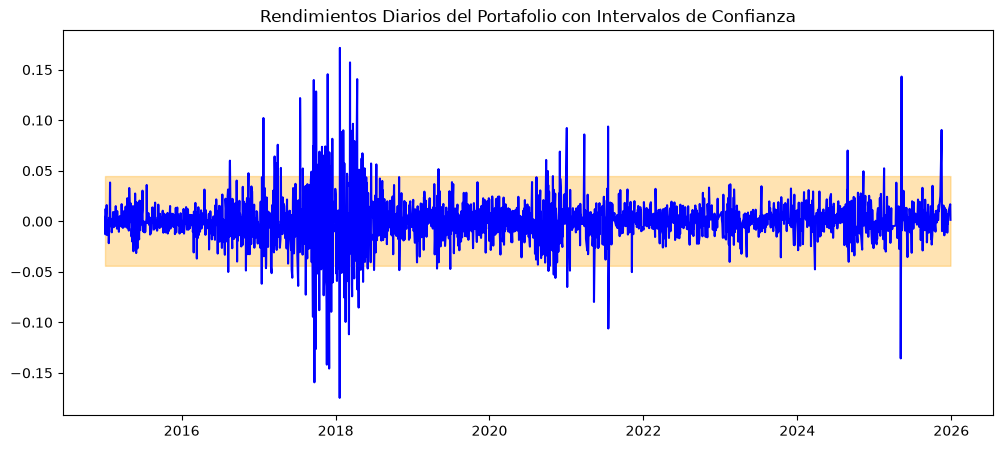

In [38]:
## Grafica de rendimientos del portafolio con intervalos de confianza
plt.figure(figsize=(12, 5))
plt.plot(df_rendimiento['Rend_Portafolio'], label='Rendimientos del Portafolio', color='blue')
plt.fill_between(df_rendimiento.index, df_rendimiento['lin_inf'], df_rendimiento['lin_sup'], color='orange', alpha=0.3, label='Intervalo de Confianza 95%')
plt.title('Rendimientos Diarios del Portafolio con Intervalos de Confianza')

In [42]:
### Volatilidad promedios moviles 

df_rendimiento['MA22_Rend'] = df_rendimiento['Rend_Portafolio'].rolling(window=22).mean().shift(1)
df_rendimiento['vola_MA22_Rend'] = df_rendimiento['Rend_Portafolio'].rolling(window=22).std().shift(1)
df_rendimiento['lin_inf_MA22'] = df_rendimiento['MA22_Rend'] - z[1]*df_rendimiento['vola_MA22_Rend']
df_rendimiento['lin_sup_MA22'] = df_rendimiento['MA22_Rend'] + z[1]*df_rendimiento['vola_MA22_Rend']


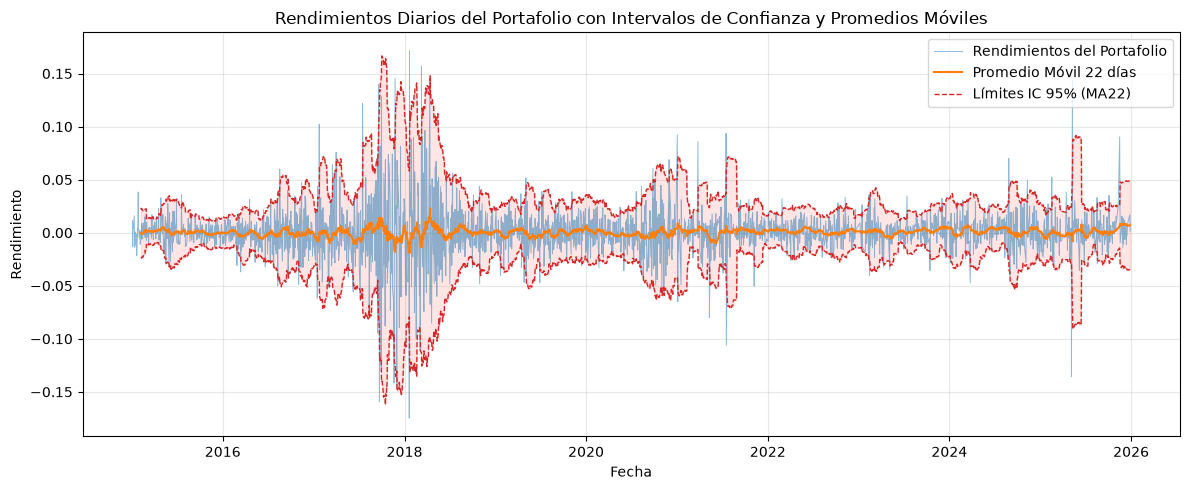

In [46]:
plt.figure(figsize=(12, 5))

# 1. Serie de rendimientos (con alpha=0.5 y línea más fina para no tapar el promedio ni las bandas)
plt.plot(df_rendimiento.index, df_rendimiento['Rend_Portafolio'], 
         label='Rendimientos del Portafolio', color='#1f77b4', linewidth=0.7, alpha=0.5)

# 2. Promedio Móvil 22 días
plt.plot(df_rendimiento.index, df_rendimiento['MA22_Rend'], 
         label='Promedio Móvil 22 días', color='#ff7f0e', linewidth=1.5)

# 3. Líneas de los límites superior e inferior (en rojo punteado para que se vean exactos como en Excel)
plt.plot(df_rendimiento.index, df_rendimiento['lin_sup_MA22'], 
         color='#d62728', linestyle='--', linewidth=1, label='Límites IC 95% (MA22)')
plt.plot(df_rendimiento.index, df_rendimiento['lin_inf_MA22'], 
         color='#d62728', linestyle='--', linewidth=1)

# 4. Sombreado entre los límites
plt.fill_between(df_rendimiento.index, df_rendimiento['lin_inf_MA22'], df_rendimiento['lin_sup_MA22'], 
                 color='#ff9896', alpha=0.25)

plt.title('Rendimientos Diarios del Portafolio con Intervalos de Confianza y Promedios Móviles')
plt.xlabel('Fecha')
plt.ylabel('Rendimiento')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()